# Student Performance & At-Risk Prediction

## Phase 3: Exploratory Data Analysis

This notebook explores the synthetic student performance dataset.

Objectives:
- Understand the dataset structure.
- Identify missing values and duplicates.
- Analyze distributions and relationships.
- Investigate academic performance patterns.
- Identify class imbalance and potential leakage.


In [1]:
import sys

print("Python executable:", sys.executable)
print("Python version:", sys.version)

Python executable: /Users/rahuljangra/Downloads/student-performance-risk-prediction/venv/bin/python
Python version: 3.11.5 (v3.11.5:cce6ba91b3, Aug 24 2023, 10:50:31) [Clang 13.0.0 (clang-1300.0.29.30)]


In [2]:

# Data manipulation
import pandas as pd
import numpy as np

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# File handling
from pathlib import Path

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.width", 120)

# Visualization settings
sns.set_theme(style="whitegrid")

# Display plots inside notebook
%matplotlib inline

print("All libraries imported successfully!")


All libraries imported successfully!


In [3]:

# Locate the project root
PROJECT_ROOT = Path.cwd().parent

# Define dataset path
DATA_PATH = (
    PROJECT_ROOT
    / "data"
    / "raw"
    / "student_performance.csv"
)

# Check whether the dataset exists
if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Dataset not found at: {DATA_PATH}"
    )

# Load CSV
df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully!")
print("Dataset location:", DATA_PATH)
print("Dataset shape:", df.shape)


Dataset loaded successfully!
Dataset location: /Users/rahuljangra/Downloads/student-performance-risk-prediction/data/raw/student_performance.csv
Dataset shape: (5000, 11)


In [5]:
df.head()


,student_id,prediction_period,prediction_date,next_assessment_date,attendance_rate,assignment_completion_rate,previous_score_1,previous_score_2,previous_score_3,next_assessment_score,at_risk_next_assessment
0,S00001,1,2025-01-01,2025-01-15,76.48,55.17,63.95,70.34,79.56,69.93,0
1,S00002,1,2025-01-01,2025-01-15,62.39,51.54,44.31,53.63,52.65,58.41,0
2,S00003,1,2025-01-01,2025-01-15,79.81,71.96,67.70,79.34,94.85,83.05,0
3,S00004,1,2025-01-01,2025-01-15,87.65,75.09,80.85,87.38,55.53,76.82,0
4,S00005,1,2025-01-01,2025-01-15,45.87,41.08,35.27,41.38,27.55,38.82,1


In [6]:
df.tail()

,student_id,prediction_period,prediction_date,next_assessment_date,attendance_rate,assignment_completion_rate,previous_score_1,previous_score_2,previous_score_3,next_assessment_score,at_risk_next_assessment
4995,S00996,5,2025-05-01,2025-05-15,68.07,76.84,71.18,73.17,70.73,73.04,0
4996,S00997,5,2025-05-01,2025-05-15,84.87,53.65,72.18,68.25,68.23,70.82,0
4997,S00998,5,2025-05-01,2025-05-15,81.72,97.79,72.08,65.14,75.18,68.42,0
4998,S00999,5,2025-05-01,2025-05-15,56.06,81.83,52.98,60.94,64.61,56.26,0
4999,S01000,5,2025-05-01,2025-05-15,99.33,78.57,64.71,61.04,58.29,69.23,0


In [7]:
df.sample(5, random_state=42)

,student_id,prediction_period,prediction_date,next_assessment_date,attendance_rate,assignment_completion_rate,previous_score_1,previous_score_2,previous_score_3,next_assessment_score,at_risk_next_assessment
1501,S00502,2,2025-02-01,2025-02-15,68.77,74.19,71.63,58.79,86.08,73.76,0
2586,S00587,3,2025-03-01,2025-03-15,44.58,60.22,34.64,47.11,38.08,37.21,1
2653,S00654,3,2025-03-01,2025-03-15,67.80,63.56,42.24,40.43,47.90,41.83,0
1055,S00056,2,2025-02-01,2025-02-15,79.24,72.82,54.61,50.17,50.01,70.10,0
705,S00706,1,2025-01-01,2025-01-15,84.09,60.57,48.15,49.27,42.58,49.79,0


In [8]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Rows: 5000
Columns: 11


In [9]:

# Display dataset information
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 11 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   student_id                  5000 non-null   str    
 1   prediction_period           5000 non-null   int64  
 2   prediction_date             5000 non-null   str    
 3   next_assessment_date        5000 non-null   str    
 4   attendance_rate             5000 non-null   float64
 5   assignment_completion_rate  5000 non-null   float64
 6   previous_score_1            5000 non-null   float64
 7   previous_score_2            5000 non-null   float64
 8   previous_score_3            5000 non-null   float64
 9   next_assessment_score       5000 non-null   float64
 10  at_risk_next_assessment     5000 non-null   int64  
dtypes: float64(6), int64(2), str(3)
memory usage: 556.8 KB


In [10]:
date_columns = [
    "prediction_date",
    "next_assessment_date"
]

for column in date_columns:
    df[column] = pd.to_datetime(
        df[column],
        errors="coerce"
    )

print(df[date_columns].dtypes)

prediction_date         datetime64[us]
next_assessment_date    datetime64[us]
dtype: object


In [11]:
df.describe()

,prediction_period,prediction_date,next_assessment_date,attendance_rate,assignment_completion_rate,previous_score_1,previous_score_2,previous_score_3,next_assessment_score,at_risk_next_assessment
count,5000.000000,5000,5000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000
mean,3.000000,2025-03-02 00:00:00,2025-03-16 00:00:00,72.306280,69.773956,62.982036,61.734842,60.776376,64.227496,0.047400
min,1.000000,2025-01-01 00:00:00,2025-01-15 00:00:00,33.280000,15.160000,8.640000,1.410000,0.000000,15.140000,0.000000
25%,2.000000,2025-02-01 00:00:00,2025-02-15 00:00:00,64.897500,60.490000,53.067500,51.240000,49.727500,54.847500,0.000000
50%,3.000000,2025-03-01 00:00:00,2025-03-15 00:00:00,72.510000,69.905000,63.290000,62.075000,61.170000,64.465000,0.000000
75%,4.000000,2025-04-01 00:00:00,2025-04-15 00:00:00,79.952500,79.340000,72.952500,72.070000,71.637500,73.702500,0.000000
max,5.000000,2025-05-01 00:00:00,2025-05-15 00:00:00,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,1.000000
std,1.414355,NaN,NaN,11.293581,13.695891,14.889756,15.482645,16.385893,14.192355,0.212514


In [12]:
numerical_features = [
    "attendance_rate",
    "assignment_completion_rate",
    "previous_score_1",
    "previous_score_2",
    "previous_score_3",
    "next_assessment_score"
]

df[numerical_features].describe().T

,count,mean,std,min,25%,50%,75%,max
attendance_rate,5000.0,72.306280,11.293581,33.28,64.8975,72.510,79.9525,100.0
assignment_completion_rate,5000.0,69.773956,13.695891,15.16,60.4900,69.905,79.3400,100.0
previous_score_1,5000.0,62.982036,14.889756,8.64,53.0675,63.290,72.9525,100.0
previous_score_2,5000.0,61.734842,15.482645,1.41,51.2400,62.075,72.0700,100.0
previous_score_3,5000.0,60.776376,16.385893,0.00,49.7275,61.170,71.6375,100.0
next_assessment_score,5000.0,64.227496,14.192355,15.14,54.8475,64.465,73.7025,100.0


In [13]:

# Count missing values in each column
missing_count = df.isnull().sum()

# Calculate missing percentage
missing_percentage = (
    df.isnull().mean() * 100
)

# Combine results
missing_analysis = pd.DataFrame({
    "Missing Count": missing_count,
    "Missing Percentage": missing_percentage
})

print(missing_analysis)


                            Missing Count  Missing Percentage
student_id                              0                 0.0
prediction_period                       0                 0.0
prediction_date                         0                 0.0
next_assessment_date                    0                 0.0
attendance_rate                         0                 0.0
assignment_completion_rate              0                 0.0
previous_score_1                        0                 0.0
previous_score_2                        0                 0.0
previous_score_3                        0                 0.0
next_assessment_score                   0                 0.0
at_risk_next_assessment                 0                 0.0


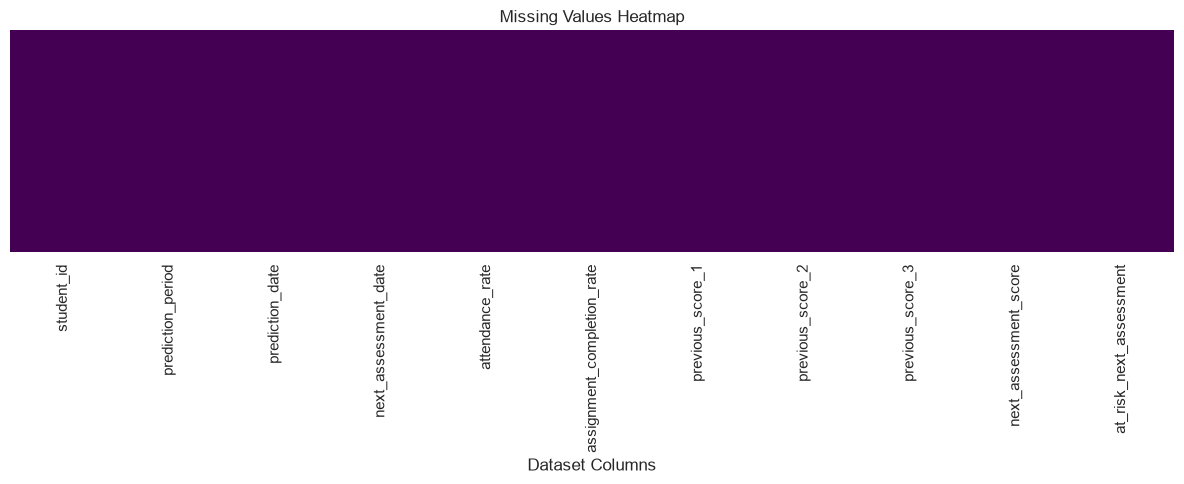

In [14]:
plt.figure(figsize=(12, 5))

sns.heatmap(
    df.isnull(),
    cbar=False,
    yticklabels=False,
    cmap="viridis"
)

plt.title("Missing Values Heatmap")
plt.xlabel("Dataset Columns")
plt.tight_layout()
plt.show()

In [15]:
# Count completely duplicated rows
duplicate_count = df.duplicated().sum()

# Check duplicate student-period combinations
duplicate_student_period = df.duplicated(
    subset=["student_id", "prediction_period"]
).sum()

print("Duplicate rows:", duplicate_count)

print(
    "Duplicate student-period records:",
    duplicate_student_period
)

Duplicate rows: 0
Duplicate student-period records: 0


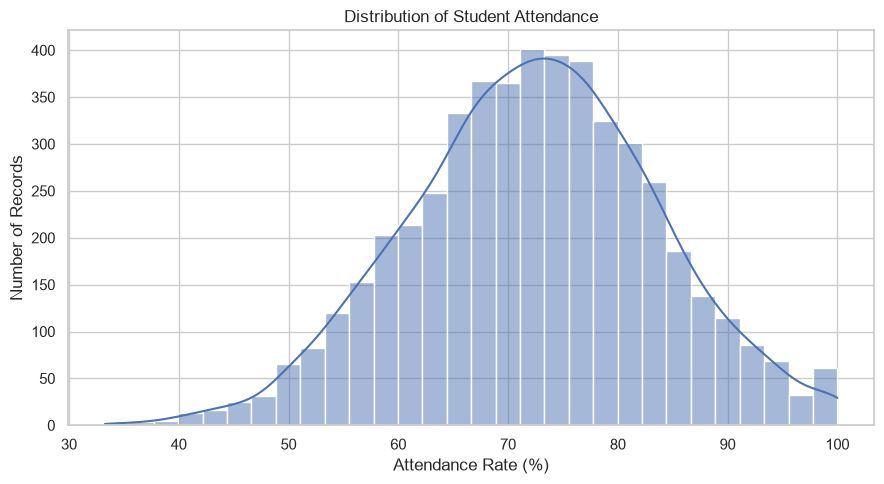

In [16]:

plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x="attendance_rate",
    bins=30,
    kde=True
)

plt.title("Distribution of Student Attendance")
plt.xlabel("Attendance Rate (%)")
plt.ylabel("Number of Records")

plt.tight_layout()
plt.savefig(
    PROJECT_ROOT / "reports/figures/attendance_distribution.png",
    dpi=300
)
plt.show()


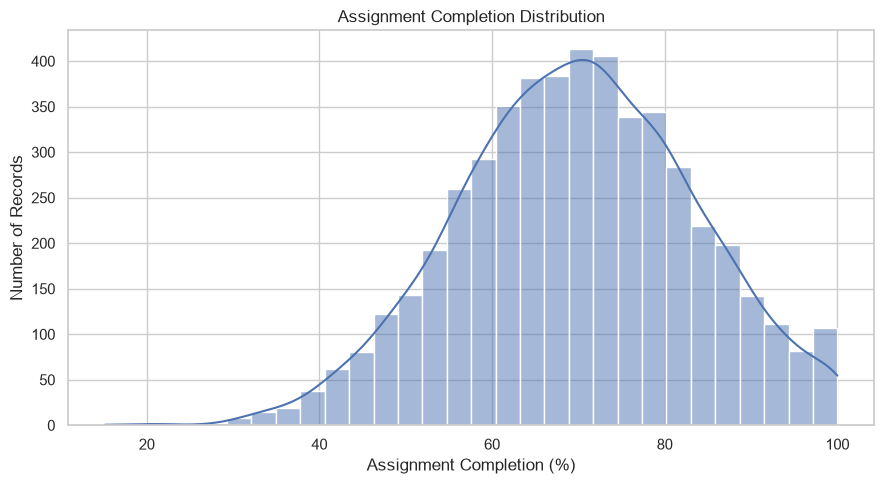

In [17]:
plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x="assignment_completion_rate",
    bins=30,
    kde=True
)

plt.title("Assignment Completion Distribution")
plt.xlabel("Assignment Completion (%)")
plt.ylabel("Number of Records")

plt.tight_layout()
plt.savefig(
    PROJECT_ROOT / "reports/figures/assignment_distribution.png",
    dpi=300
)
plt.show()

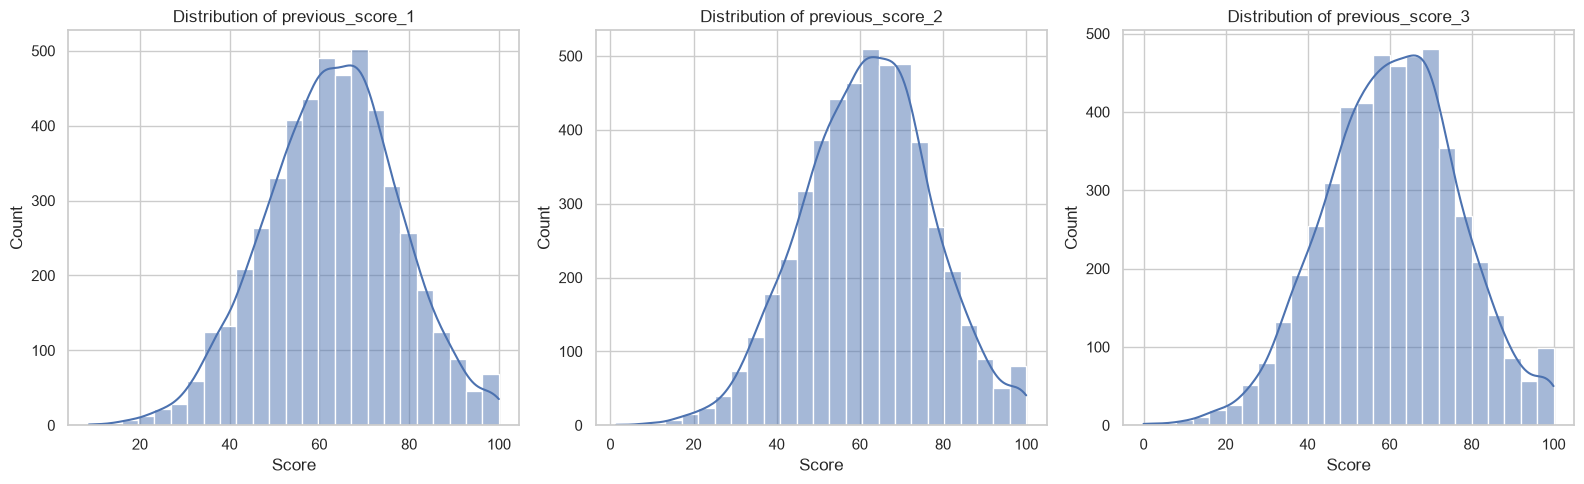

In [18]:
fig, axes = plt.subplots(
    1, 3,
    figsize=(16, 5)
)

score_columns = [
    "previous_score_1",
    "previous_score_2",
    "previous_score_3"
]

for ax, column in zip(axes, score_columns):

    sns.histplot(
        data=df,
        x=column,
        bins=25,
        kde=True,
        ax=ax
    )

    ax.set_title(f"Distribution of {column}")
    ax.set_xlabel("Score")

plt.tight_layout()

plt.savefig(
    PROJECT_ROOT / "reports/figures/previous_scores_distribution.png",
    dpi=300
)

plt.show()

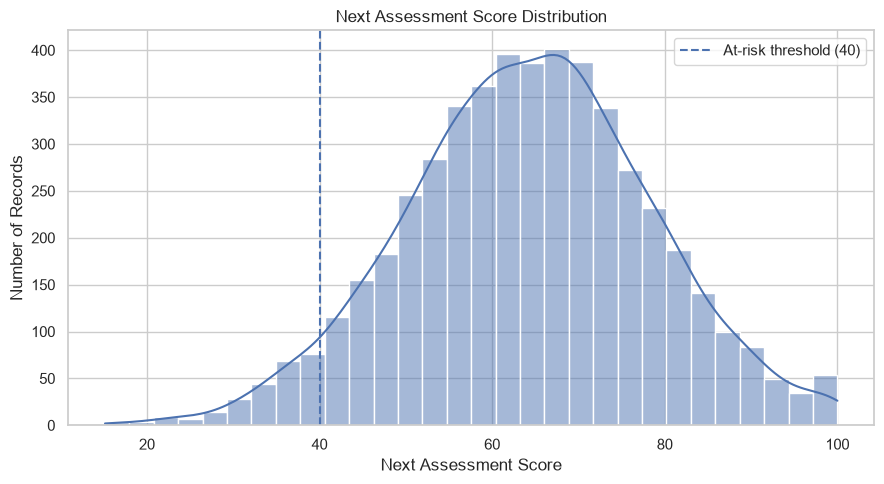

In [19]:
plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x="next_assessment_score",
    bins=30,
    kde=True
)

plt.axvline(
    x=40,
    linestyle="--",
    label="At-risk threshold (40)"
)

plt.title("Next Assessment Score Distribution")
plt.xlabel("Next Assessment Score")
plt.ylabel("Number of Records")

plt.legend()

plt.tight_layout()

plt.savefig(
    PROJECT_ROOT / "reports/figures/next_score_distribution.png",
    dpi=300
)

plt.show()

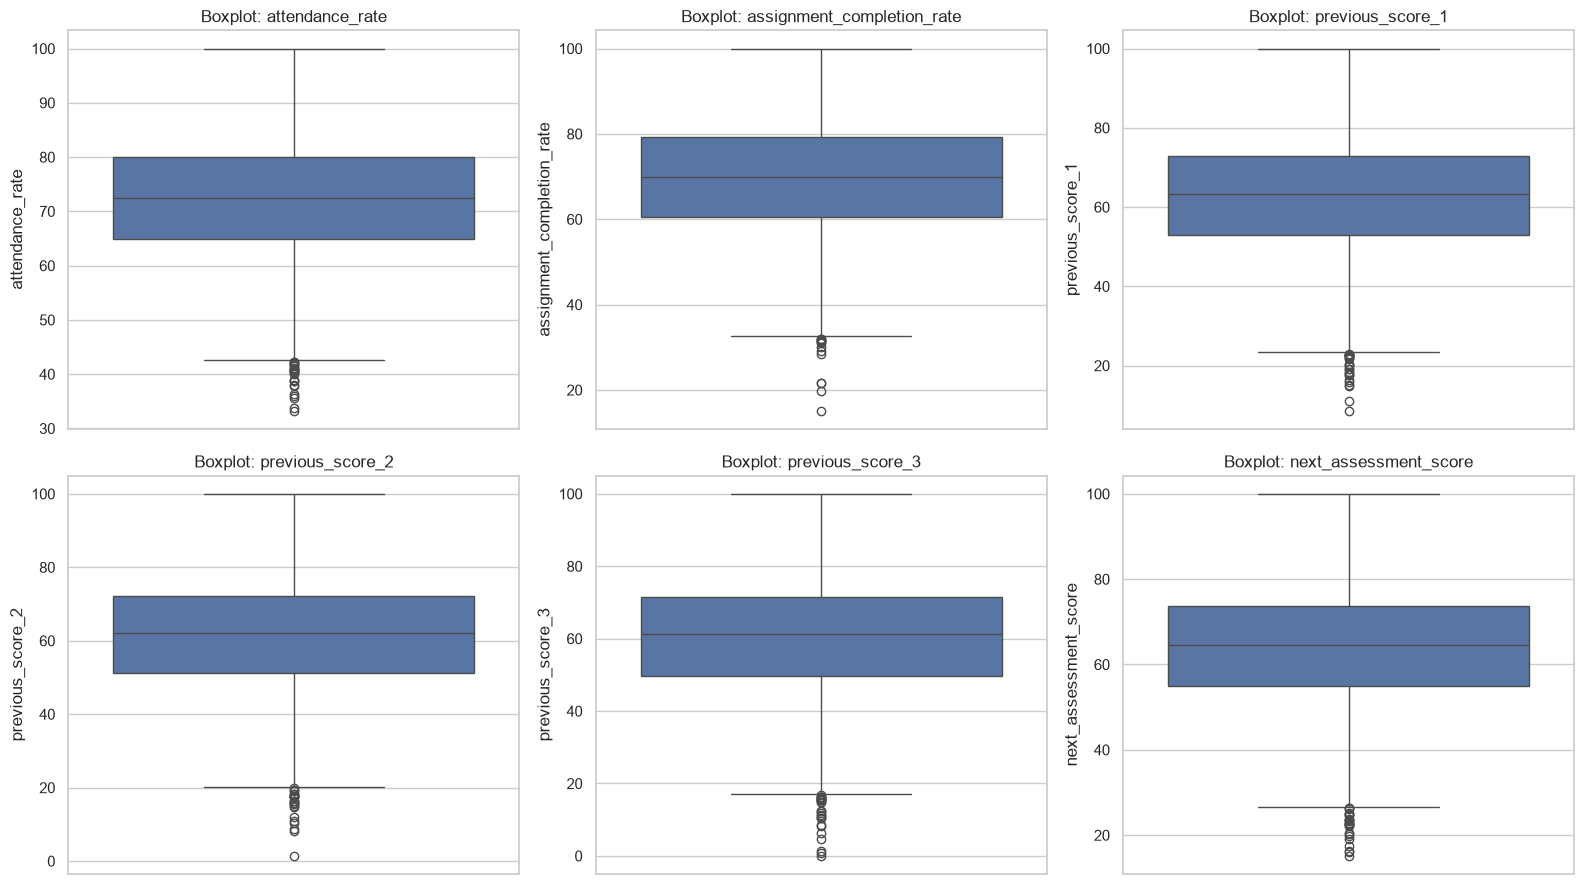

In [20]:

outlier_features = [
    "attendance_rate",
    "assignment_completion_rate",
    "previous_score_1",
    "previous_score_2",
    "previous_score_3",
    "next_assessment_score"
]

fig, axes = plt.subplots(
    2, 3,
    figsize=(16, 9)
)

for ax, column in zip(
    axes.flatten(),
    outlier_features
):

    sns.boxplot(
        data=df,
        y=column,
        ax=ax
    )

    ax.set_title(f"Boxplot: {column}")

plt.tight_layout()

plt.savefig(
    PROJECT_ROOT / "reports/figures/outlier_analysis.png",
    dpi=300
)

plt.show()


In [21]:
outlier_summary = []

for column in outlier_features:

    Q1 = df[column].quantile(0.25)

    Q3 = df[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR

    upper_bound = Q3 + 1.5 * IQR

    outliers = df[
        (df[column] < lower_bound) |
        (df[column] > upper_bound)
    ]

    outlier_summary.append({
        "Feature": column,
        "Lower Bound": lower_bound,
        "Upper Bound": upper_bound,
        "Outlier Count": len(outliers)
    })

outlier_df = pd.DataFrame(outlier_summary)

outlier_df

,Feature,Lower Bound,Upper Bound,Outlier Count
0,attendance_rate,42.3150,102.5350,25
1,assignment_completion_rate,32.2150,107.6150,14
2,previous_score_1,23.2400,102.7800,24
3,previous_score_2,19.9950,103.3150,23
4,previous_score_3,16.8625,104.5025,26
5,next_assessment_score,26.5650,101.9850,25


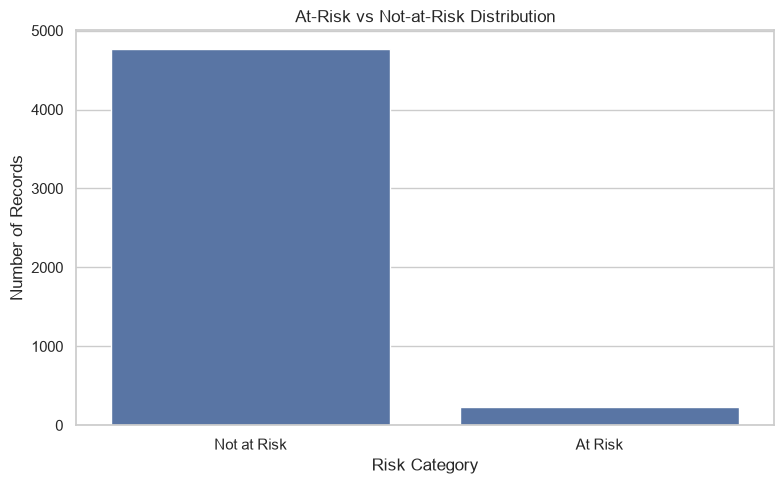

In [22]:

plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="at_risk_next_assessment"
)

plt.title("At-Risk vs Not-at-Risk Distribution")

plt.xlabel("Risk Category")
plt.ylabel("Number of Records")

plt.xticks(
    ticks=[0, 1],
    labels=["Not at Risk", "At Risk"]
)

plt.tight_layout()

plt.savefig(
    PROJECT_ROOT / "reports/figures/class_distribution.png",
    dpi=300
)

plt.show()


In [23]:
class_distribution = (
    df["at_risk_next_assessment"]
    .value_counts()
    .sort_index()
)

class_percentage = (
    df["at_risk_next_assessment"]
    .value_counts(normalize=True)
    .sort_index() * 100
)

class_analysis = pd.DataFrame({
    "Count": class_distribution,
    "Percentage": class_percentage
})

class_analysis.index = [
    "Not at Risk",
    "At Risk"
]

class_analysis

,Count,Percentage
Not at Risk,4763,95.26
At Risk,237,4.74


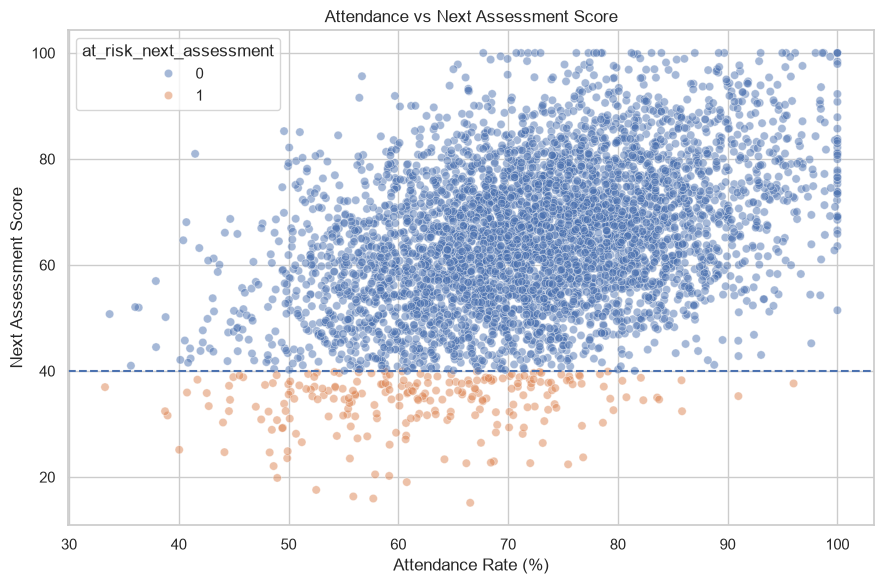

In [24]:

plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=df,
    x="attendance_rate",
    y="next_assessment_score",
    hue="at_risk_next_assessment",
    alpha=0.5
)

plt.axhline(
    y=40,
    linestyle="--",
    label="At-risk threshold"
)

plt.title("Attendance vs Next Assessment Score")
plt.xlabel("Attendance Rate (%)")
plt.ylabel("Next Assessment Score")

plt.tight_layout()

plt.savefig(
    PROJECT_ROOT / "reports/figures/attendance_vs_score.png",
    dpi=300
)

plt.show()


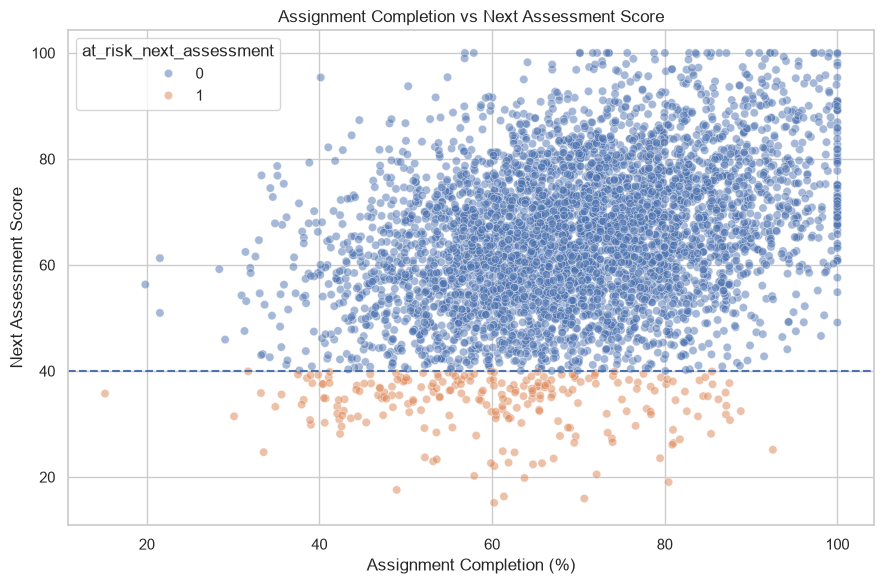

In [25]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=df,
    x="assignment_completion_rate",
    y="next_assessment_score",
    hue="at_risk_next_assessment",
    alpha=0.5
)

plt.axhline(
    y=40,
    linestyle="--"
)

plt.title("Assignment Completion vs Next Assessment Score")

plt.xlabel("Assignment Completion (%)")
plt.ylabel("Next Assessment Score")

plt.tight_layout()

plt.savefig(
    PROJECT_ROOT / "reports/figures/assignment_vs_score.png",
    dpi=300
)

plt.show()


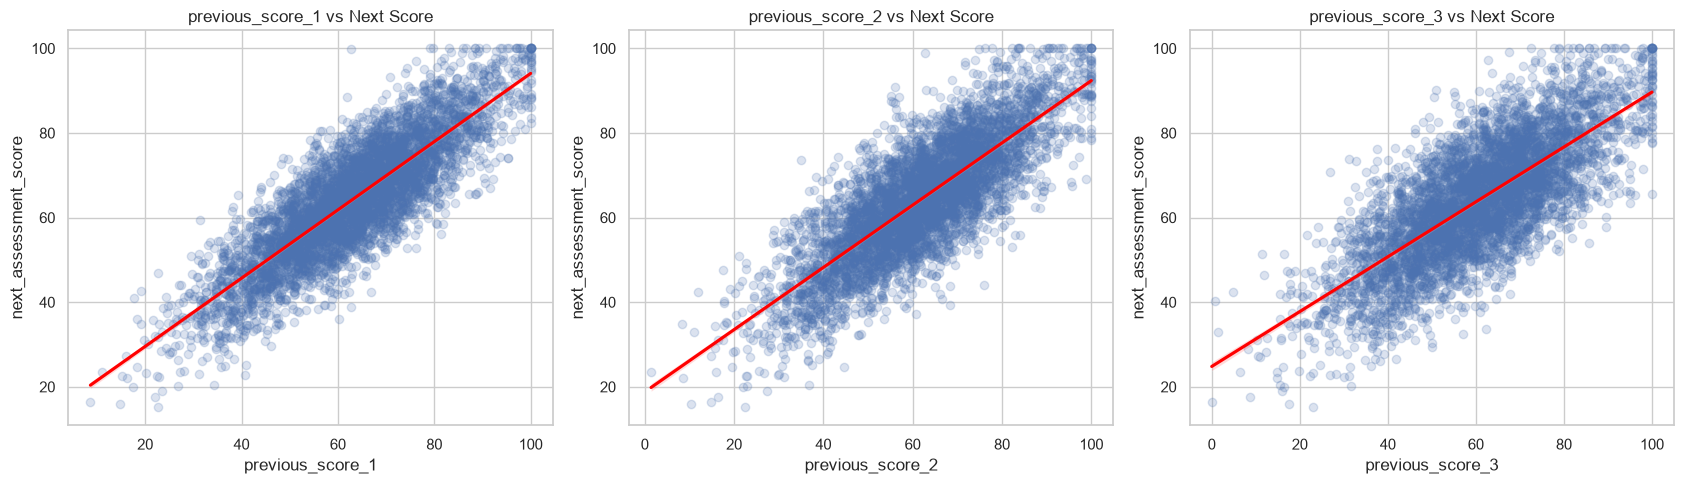

In [26]:
fig, axes = plt.subplots(
    1, 3,
    figsize=(17, 5)
)

score_columns = [
    "previous_score_1",
    "previous_score_2",
    "previous_score_3"
]

for ax, column in zip(axes, score_columns):

    sns.regplot(
        data=df,
        x=column,
        y="next_assessment_score",
        scatter_kws={"alpha": 0.2},
        line_kws={"color": "red"},
        ax=ax
    )

    ax.set_title(f"{column} vs Next Score")

plt.tight_layout()

plt.savefig(
    PROJECT_ROOT / "reports/figures/previous_vs_next_score.png",
    dpi=300
)

plt.show()

In [27]:
comparison = (
    df.groupby("at_risk_next_assessment")[
        [
            "attendance_rate",
            "assignment_completion_rate",
            "previous_score_1",
            "previous_score_2",
            "previous_score_3",
            "next_assessment_score"
        ]
    ]
    .mean()
    .round(2)
)

comparison.index = [
    "Not at Risk",
    "At Risk"
]

comparison

,attendance_rate,assignment_completion_rate,previous_score_1,previous_score_2,previous_score_3,next_assessment_score
Not at Risk,72.81,70.24,64.35,63.08,62.10,65.74
At Risk,62.15,60.35,35.50,34.73,34.18,33.93


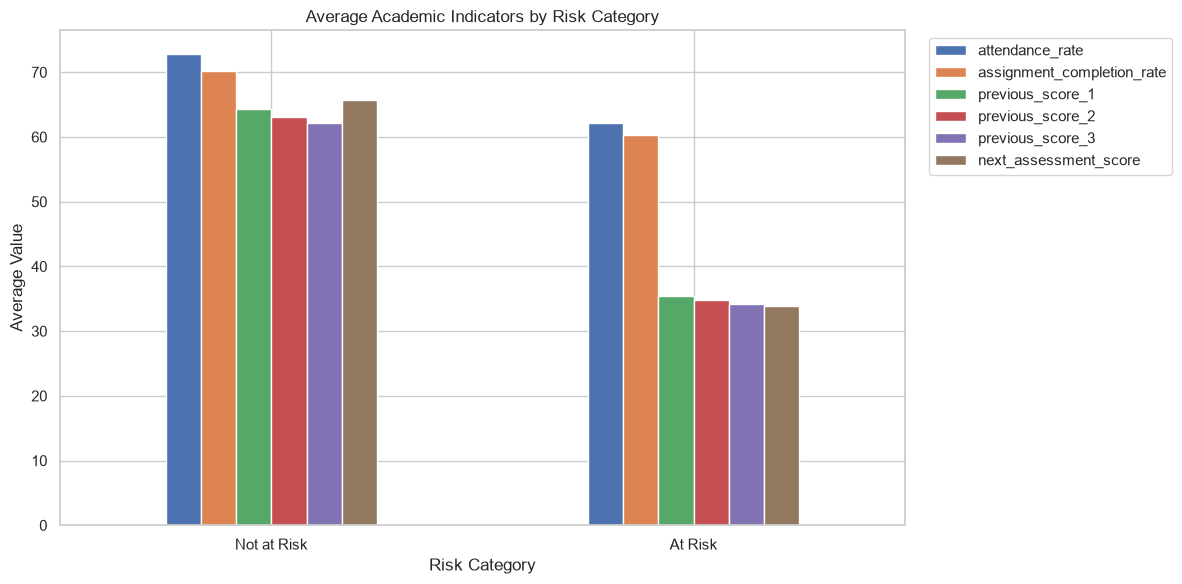

In [28]:
comparison.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Average Academic Indicators by Risk Category")

plt.ylabel("Average Value")

plt.xlabel("Risk Category")

plt.xticks(rotation=0)

plt.legend(
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout()

plt.savefig(
    PROJECT_ROOT / "reports/figures/risk_group_comparison.png",
    dpi=300
)

plt.show()

In [29]:

correlation_features = [
    "attendance_rate",
    "assignment_completion_rate",
    "previous_score_1",
    "previous_score_2",
    "previous_score_3",
    "next_assessment_score",
    "at_risk_next_assessment"
]

correlation_matrix = df[
    correlation_features
].corr()

correlation_matrix.round(2)


,attendance_rate,assignment_completion_rate,previous_score_1,previous_score_2,previous_score_3,next_assessment_score,at_risk_next_assessment
attendance_rate,1.00,0.12,0.38,0.38,0.37,0.42,-0.20
assignment_completion_rate,0.12,1.00,0.32,0.31,0.30,0.35,-0.15
previous_score_1,0.38,0.32,1.00,0.84,0.78,0.85,-0.41
previous_score_2,0.38,0.31,0.84,1.00,0.83,0.80,-0.39
previous_score_3,0.37,0.30,0.78,0.83,1.00,0.75,-0.36
next_assessment_score,0.42,0.35,0.85,0.80,0.75,1.00,-0.48
at_risk_next_assessment,-0.20,-0.15,-0.41,-0.39,-0.36,-0.48,1.00


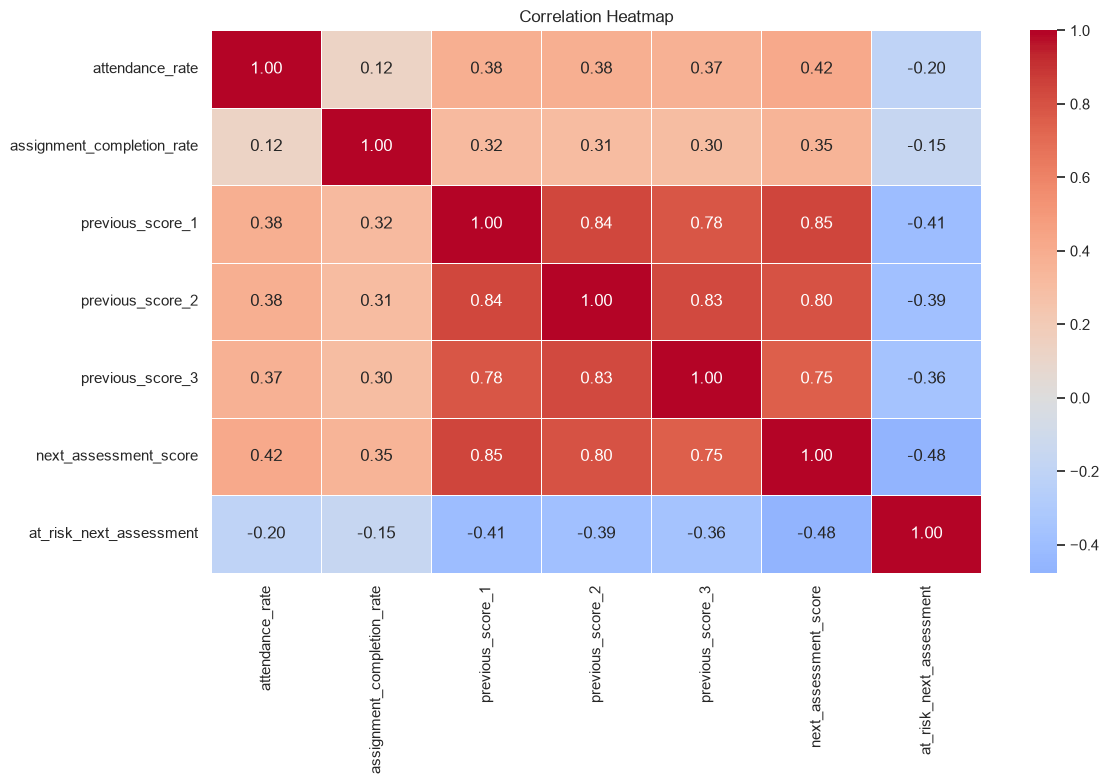

In [30]:
plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5,
    center=0
)

plt.title("Correlation Heatmap")

plt.tight_layout()

plt.savefig(
    PROJECT_ROOT / "reports/figures/correlation_heatmap.png",
    dpi=300
)

plt.show()

In [31]:

period_analysis = (
    df.groupby("prediction_period")
    .agg(
        average_attendance=("attendance_rate", "mean"),
        average_assignment_completion=(
            "assignment_completion_rate", "mean"
        ),
        average_previous_score=(
            "previous_score_1", "mean"
        ),
        average_next_score=(
            "next_assessment_score", "mean"
        ),
        at_risk_count=(
            "at_risk_next_assessment", "sum"
        ),
        total_records=(
            "student_id", "count"
        )
    )
    .round(2)
)

period_analysis["at_risk_percentage"] = (
    period_analysis["at_risk_count"]
    / period_analysis["total_records"]
    * 100
).round(2)

period_analysis


,average_attendance,average_assignment_completion,average_previous_score,average_next_score,at_risk_count,total_records,at_risk_percentage
prediction_period,,,,,,,
1,73.23,69.80,59.85,62.20,72,1000,7.2
2,72.52,69.75,62.20,63.10,59,1000,5.9
3,72.11,69.86,63.10,64.20,46,1000,4.6
4,71.96,69.70,64.20,65.56,34,1000,3.4
5,71.71,69.76,65.56,66.08,26,1000,2.6


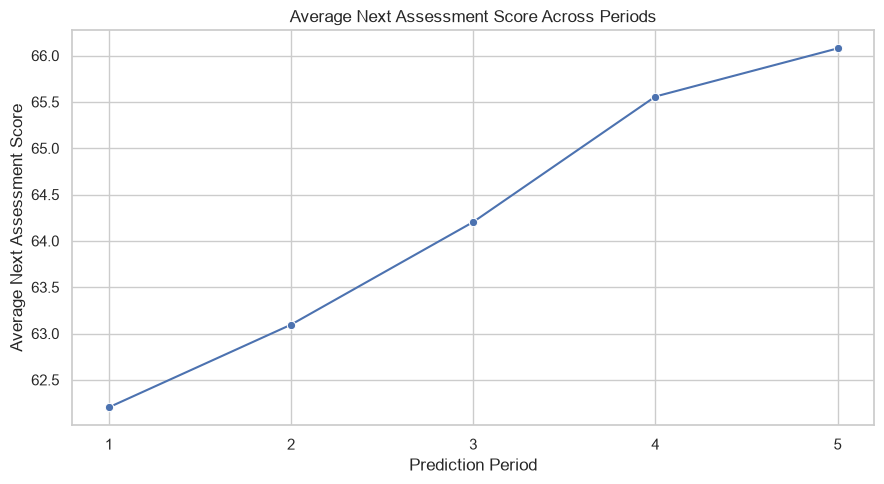

In [32]:
plt.figure(figsize=(9, 5))

sns.lineplot(
    data=df,
    x="prediction_period",
    y="next_assessment_score",
    estimator="mean",
    errorbar=None,
    marker="o"
)

plt.title("Average Next Assessment Score Across Periods")

plt.xlabel("Prediction Period")
plt.ylabel("Average Next Assessment Score")

plt.xticks([1, 2, 3, 4, 5])

plt.tight_layout()

plt.savefig(
    PROJECT_ROOT / "reports/figures/period_performance.png",
    dpi=300
)

plt.show()

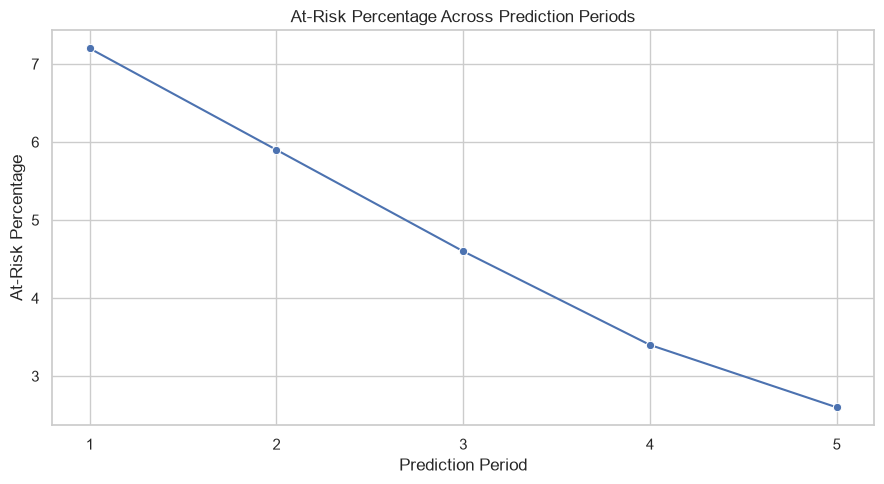

In [33]:
plt.figure(figsize=(9, 5))

sns.lineplot(
    data=period_analysis.reset_index(),
    x="prediction_period",
    y="at_risk_percentage",
    marker="o"
)

plt.title("At-Risk Percentage Across Prediction Periods")

plt.xlabel("Prediction Period")
plt.ylabel("At-Risk Percentage")

plt.xticks([1, 2, 3, 4, 5])

plt.tight_layout()

plt.savefig(
    PROJECT_ROOT / "reports/figures/period_risk_trend.png",
    dpi=300
)

plt.show()

In [34]:

# Approved initial predictive features
MODEL_FEATURES = [
    "attendance_rate",
    "assignment_completion_rate",
    "previous_score_1",
    "previous_score_2",
    "previous_score_3"
]

# Target
TARGET = "at_risk_next_assessment"

# Future outcome must never be an input.
FORBIDDEN_FEATURES = [
    "next_assessment_score",
    TARGET,
    "student_id"
]

assert TARGET not in MODEL_FEATURES

assert "next_assessment_score" not in MODEL_FEATURES

assert not (
    set(MODEL_FEATURES) & set(FORBIDDEN_FEATURES)
)

assert df[MODEL_FEATURES].notnull().all().all()

print("Leakage checks passed!")
print("\nApproved model features:")
print(MODEL_FEATURES)

print("\nTarget:")
print(TARGET)


Leakage checks passed!

Approved model features:
['attendance_rate', 'assignment_completion_rate', 'previous_score_1', 'previous_score_2', 'previous_score_3']

Target:
at_risk_next_assessment


In [35]:
FIGURES_DIR = PROJECT_ROOT / "reports" / "figures"

FIGURES_DIR.mkdir(
    parents=True,
    exist_ok=True
)

In [36]:

# Overall dataset information

eda_summary = {
    "Total Records": len(df),

    "Unique Students": df["student_id"].nunique(),

    "Prediction Periods": (
        df["prediction_period"].nunique()
    ),

    "Total Features": len(MODEL_FEATURES),

    "Missing Values": int(df.isnull().sum().sum()),

    "Duplicate Rows": int(df.duplicated().sum()),

    "At-Risk Records": int(
        df[TARGET].sum()
    ),

    "Not-at-Risk Records": int(
        (df[TARGET] == 0).sum()
    ),

    "At-Risk Percentage": round(
        df[TARGET].mean() * 100, 2
    ),

    "Average Attendance": round(
        df["attendance_rate"].mean(), 2
    ),

    "Average Assignment Completion": round(
        df["assignment_completion_rate"].mean(), 2
    ),

    "Average Next Assessment Score": round(
        df["next_assessment_score"].mean(), 2
    )
}

eda_summary_df = pd.DataFrame(
    eda_summary.items(),
    columns=["Metric", "Value"]
)

display(eda_summary_df)

# Save summary
eda_summary_df.to_csv(
    PROJECT_ROOT / "reports" / "eda_summary.csv",
    index=False
)

print("EDA summary saved successfully!")


,Metric,Value
0,Total Records,5000.00
1,Unique Students,1000.00
2,Prediction Periods,5.00
3,Total Features,5.00
4,Missing Values,0.00
5,Duplicate Rows,0.00
6,At-Risk Records,237.00
7,Not-at-Risk Records,4763.00
8,At-Risk Percentage,4.74
9,Average Attendance,72.31


EDA summary saved successfully!


In [38]:
# Load engineered dataset

features_path = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "student_performance_features.csv"
)

df_features = pd.read_csv(
    features_path
)

print("Shape:", df_features.shape)

print("\nNew feature columns:")

new_features = [
    "average_previous_score",
    "score_trend",
    "recent_score_change",
    "score_volatility"
]

display(
    df_features[
        [
            "student_id",
            "previous_score_1",
            "previous_score_2",
            "previous_score_3",
            *new_features
        ].head(10)
    ]
)

Shape: (5000, 15)

New feature columns:


AttributeError: 'list' object has no attribute 'head'

In [39]:
sample = df_features.iloc[0]

manual_average = (
    sample["previous_score_1"]
    + sample["previous_score_2"]
    + sample["previous_score_3"]
) / 3

print("Calculated average:", manual_average)

print(
    "Stored average:",
    sample["average_previous_score"]
)

Calculated average: 71.28333333333335
Stored average: 71.28333333333335


In [40]:
print("Original features:")

display(
    df_features[
        [
            "attendance_rate",
            "assignment_completion_rate",
            "previous_score_1",
            "previous_score_2",
            "previous_score_3"
        ]
    ].describe().T
)

print("\nEngineered features:")

display(
    df_features[new_features].describe().T
)

Original features:


,count,mean,std,min,25%,50%,75%,max
attendance_rate,5000.0,72.306280,11.293581,33.28,64.8975,72.510,79.9525,100.0
assignment_completion_rate,5000.0,69.773956,13.695891,15.16,60.4900,69.905,79.3400,100.0
previous_score_1,5000.0,62.982036,14.889756,8.64,53.0675,63.290,72.9525,100.0
previous_score_2,5000.0,61.734842,15.482645,1.41,51.2400,62.075,72.0700,100.0
previous_score_3,5000.0,60.776376,16.385893,0.00,49.7275,61.170,71.6375,100.0



Engineered features:


,count,mean,std,min,25%,50%,75%,max
average_previous_score,5000.0,61.831085,14.605634,6.26,52.115000,62.276667,71.545833,100.000000
score_trend,5000.0,1.102830,5.214386,-25.08,-2.280000,1.035000,4.511250,20.050000
recent_score_change,5000.0,1.247194,8.545628,-50.50,-4.540000,1.310000,6.940000,37.050000
score_volatility,5000.0,4.837983,2.717569,0.00,2.827587,4.449759,6.396501,23.726196
